Total execution time: 0.816192 s


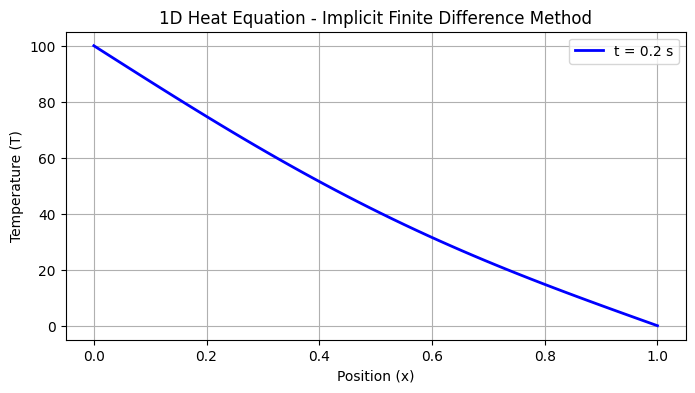

In [1]:
import time
import matplotlib.pyplot as plt
import numpy as np

# Spatial and temporal grid parameters
N = 50
n = N - 2
L = 1.0
alpha = 1.0
h = L / (N - 1)
dt = 0.001
t_final = 0.2
num_steps = int(round(t_final / dt))
r = alpha * dt / (h * h)

# Boundary conditions
T_left = 100.0
T_right = 0.0

x = np.linspace(0, L, N)
T = np.zeros(N)
T[0] = T_left
T[-1] = T_right

# Construct tridiagonal matrix A
A = np.zeros((n, n))
for i in range(n):
    A[i, i] = 1.0 + 2.0 * r
    if i > 0:
        A[i, i - 1] = -r
    if i < n - 1:
        A[i, i + 1] = -r

start_total = time.perf_counter()

# Time integration loop (Implicit Euler)
for step in range(1, num_steps + 1):
    rhs = T[1:-1].copy()
    rhs[0] += r * T_left
    rhs[-1] += r * T_right

    # Augmented matrix [A | rhs]
    M = np.column_stack((A.copy(), rhs.copy()))

    # Forward Gaussian elimination
    for k in range(n - 1):
        for i in range(k + 1, n):
            factor = M[i, k] / M[k, k]
            M[i, k:] -= factor * M[k, k:]

    # Back-substitution
    T_interior = np.zeros(n)
    for i in range(n - 1, -1, -1):
        T_interior[i] = (
            M[i, n] - np.dot(M[i, i + 1 : n], T_interior[i + 1 : n])
        ) / M[i, i]

    T[1:-1] = T_interior

end_total = time.perf_counter()
print(f"Total execution time: {end_total - start_total:.6f} s")

# Plot results
plt.figure(figsize=(8, 4))
plt.plot(x, T, "b-", linewidth=2, label=f"t = {t_final} s")
plt.xlabel("Position (x)")
plt.ylabel("Temperature (T)")
plt.title("1D Heat Equation - Implicit Finite Difference Method")
plt.grid(True)
plt.legend()
plt.show()